# Josiah Davis Notebook
# P2 Phase 5: Sportsbook App Reviews

- Author: [Josiah Davis](https://github.com/jgdavis24/)
- Repository: [nlp-02-text-preprocessing-custom](https://github.com/jgdavis24/nlp-02-text-preprocessing-custom/)
- Purpose: Apply the preprocessing pipeline and the short-token allowlist to sportsbook app reviews.
- Date: 2026-11

## The New Problem

I work in marketing acquisition for a sportsbook, so I wanted to try this on
the kind of text that comes up there: app reviews and signup feedback.

The data is **15 fictional sportsbook app reviews** in `data/sportsbook_reviews.txt`.
I wrote them with AI assistance for this class project. They don't name a real
company and aren't real customer reviews.

The question: **does the default 3-character rule throw away information that
matters in this kind of text?** State codes like PA, NJ, and MI tell you where
a problem happened, and "ID" shows up a lot in verification complaints.

In [1]:
# Section 1. Setup and Imports

from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


In [2]:
# Section 2. Read the Sportsbook Review Data

NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent
DATA_PATH: Path = ROOT_PATH / "data"

input_path: Path = DATA_PATH / "sportsbook_reviews.txt"
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()
text_list = [line.strip() for line in text_list if line.strip()]

raw_text: str = " ".join(text_list)
print(f"Loaded {len(text_list):,} reviews from {input_path.name}.")
print()
for line in text_list[:5]:
    print("-", line)

Loaded 15 reviews from sportsbook_reviews.txt.

- Signed up in PA and my first deposit went through in seconds, no issues at all.
- Withdrawal took 5 days in NJ, way too slow for a so called instant payout.
- The welcome bonus was easy to claim but the terms were not clear.
- App keeps logging me out during live games, super frustrating.
- ID verification failed twice before it finally went through.


In [3]:
# Section 3. Tokenize, Lowercase, and Remove Punctuation

raw_tokens: list[str] = raw_text.split()
lower_text: str = raw_text.lower()
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)
tokens_no_punct: list[str] = no_punct_text.split()

print(f"Raw tokens: {len(raw_tokens):,}")
print(f"Tokens after punctuation removal: {len(tokens_no_punct):,}")

Raw tokens: 186
Tokens after punctuation removal: 186


In [4]:
# Section 4. Stop Words, Short-Token Allowlist, and Cleaning Rules

# Same stop word list as the original example.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# NEW: short tokens worth keeping even though they are only 2 characters.
# State codes matter in sportsbook data, and "id" and "no" carry meaning.
KEEP_SHORT: set[str] = {"pa", "nj", "mi", "nv", "ny", "id", "no"}


def clean_tokens(
    tokens: list[str], min_len: int, keep_short: set[str] | None = None
) -> list[str]:
    """Return tokens that pass the length filter and are not stop words.

    Tokens in keep_short are kept even if they are shorter than min_len.
    """
    allow: set[str] = keep_short or set()
    return [
        token
        for token in tokens
        if (len(token) >= min_len or token in allow) and token not in STOP_WORDS
    ]


# Three rules to compare.
RULES: dict[str, dict] = {
    "A. original (3+ chars)": {"min_len": 3, "keep_short": None},
    "B. all 2+ chars": {"min_len": 2, "keep_short": None},
    "C. 3+ chars plus allowlist": {"min_len": 3, "keep_short": KEEP_SHORT},
}

results: dict[str, list[str]] = {
    name: clean_tokens(tokens_no_punct, **settings) for name, settings in RULES.items()
}

print("Cleaning rules defined.")

Cleaning rules defined.


In [5]:
# Section 5. Compare the Three Rules

summary_df: pl.DataFrame = pl.DataFrame(
    {
        "rule": list(results.keys()),
        "clean_tokens": [len(toks) for toks in results.values()],
        "unique_terms": [len(set(toks)) for toks in results.values()],
    }
)

print(f"Raw tokens: {len(raw_tokens):,}")
print(f"After lowercasing and punctuation removal: {len(tokens_no_punct):,}")
print()
print(summary_df)

Raw tokens: 186
After lowercasing and punctuation removal: 186

shape: (3, 3)
┌────────────────────────────┬──────────────┬──────────────┐
│ rule                       ┆ clean_tokens ┆ unique_terms │
│ ---                        ┆ ---          ┆ ---          │
│ str                        ┆ i64          ┆ i64          │
╞════════════════════════════╪══════════════╪══════════════╡
│ A. original (3+ chars)     ┆ 119          ┆ 96           │
│ B. all 2+ chars            ┆ 136          ┆ 105          │
│ C. 3+ chars plus allowlist ┆ 130          ┆ 101          │
└────────────────────────────┴──────────────┴──────────────┘


In [6]:
# Section 6. Which Terms Did Each Rule Add Compared to the Original?

baseline: set[str] = set(results["A. original (3+ chars)"])

for name, toks in results.items():
    if name.startswith("A."):
        continue
    added: list[str] = [t for t in toks if t not in baseline]
    if added:
        added_df: pl.DataFrame = (
            pl.DataFrame({"token": added})
            .group_by("token")
            .len()
            .sort(["len", "token"], descending=[True, False])
        )
        print(f"{name} added {len(added)} tokens:")
        print(added_df)
    else:
        print(f"{name} added no new tokens.")
    print()

B. all 2+ chars added 17 tokens:
shape: (9, 2)
┌───────┬─────┐
│ token ┆ len │
│ ---   ┆ --- │
│ str   ┆ u64 │
╞═══════╪═════╡
│ my    ┆ 3   │
│ pa    ┆ 3   │
│ id    ┆ 2   │
│ mi    ┆ 2   │
│ nj    ┆ 2   │
│ no    ┆ 2   │
│ me    ┆ 1   │
│ so    ┆ 1   │
│ up    ┆ 1   │
└───────┴─────┘

C. 3+ chars plus allowlist added 11 tokens:
shape: (5, 2)
┌───────┬─────┐
│ token ┆ len │
│ ---   ┆ --- │
│ str   ┆ u64 │
╞═══════╪═════╡
│ pa    ┆ 3   │
│ id    ┆ 2   │
│ mi    ┆ 2   │
│ nj    ┆ 2   │
│ no    ┆ 2   │
└───────┴─────┘



In [7]:
# Section 7. Audit the Short Tokens the Original Rule Drops

# Every 1-2 character token, and the reason it gets removed by the original rule.
short_df: pl.DataFrame = (
    pl.DataFrame({"token": [t for t in tokens_no_punct if len(t) <= 2]})
    .group_by("token")
    .len()
    .with_columns(
        pl.when(pl.col("token").is_in(list(STOP_WORDS)))
        .then(pl.lit("stop word"))
        .when(pl.col("token").is_in(list(KEEP_SHORT)))
        .then(pl.lit("allowlist keeps it"))
        .otherwise(pl.lit("too short"))
        .alias("reason")
    )
    .sort(["len", "token"], descending=[True, False])
)

print(f"Short tokens found: {short_df['len'].sum()} ({short_df.height} unique)")
with pl.Config(tbl_rows=30):
    print(short_df)

Short tokens found: 43 (17 unique)
shape: (17, 3)
┌───────┬─────┬────────────────────┐
│ token ┆ len ┆ reason             │
│ ---   ┆ --- ┆ ---                │
│ str   ┆ u64 ┆ str                │
╞═══════╪═════╪════════════════════╡
│ in    ┆ 7   ┆ stop word          │
│ i     ┆ 4   ┆ too short          │
│ is    ┆ 4   ┆ stop word          │
│ to    ┆ 4   ┆ stop word          │
│ a     ┆ 3   ┆ stop word          │
│ my    ┆ 3   ┆ too short          │
│ pa    ┆ 3   ┆ allowlist keeps it │
│ at    ┆ 2   ┆ stop word          │
│ id    ┆ 2   ┆ allowlist keeps it │
│ mi    ┆ 2   ┆ allowlist keeps it │
│ nj    ┆ 2   ┆ allowlist keeps it │
│ no    ┆ 2   ┆ allowlist keeps it │
│ 5     ┆ 1   ┆ too short          │
│ it    ┆ 1   ┆ stop word          │
│ me    ┆ 1   ┆ too short          │
│ so    ┆ 1   ┆ too short          │
│ up    ┆ 1   ┆ too short          │
└───────┴─────┴────────────────────┘


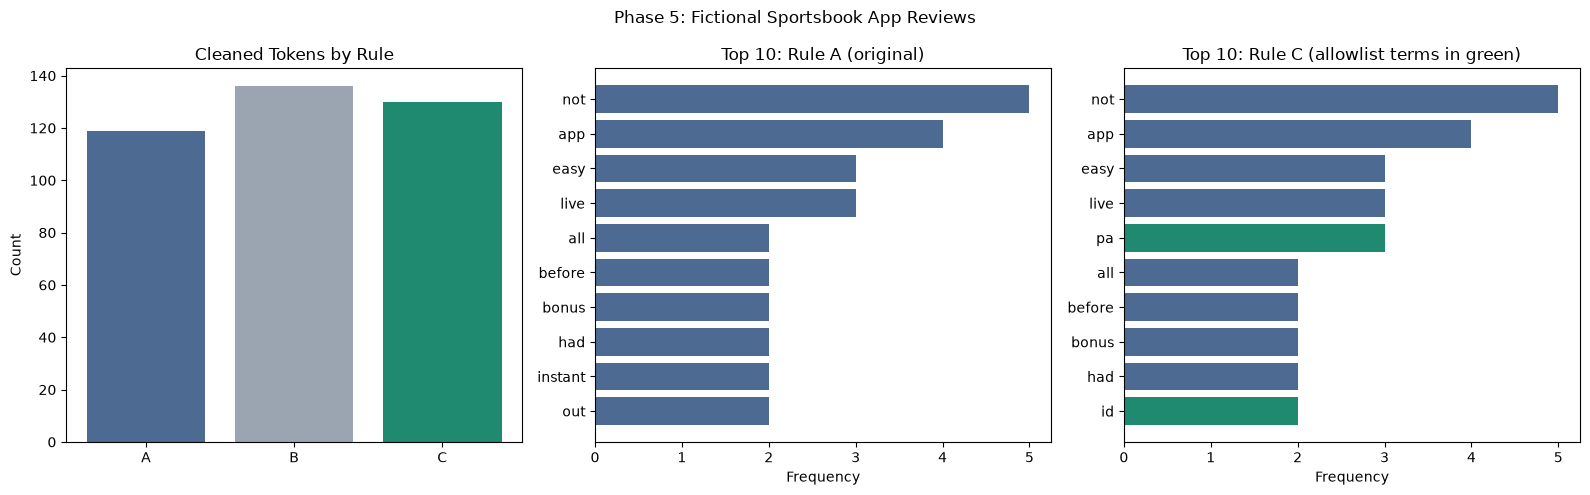

In [8]:
# Section 8. Visualize the Results

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

ax1.bar(
    ["A", "B", "C"],
    summary_df["clean_tokens"].to_list(),
    color=["#4C6A92", "#9AA5B1", "#1F8A70"],
)
ax1.set_title("Cleaned Tokens by Rule")
ax1.set_ylabel("Count")

top_a: pl.DataFrame = (
    pl.DataFrame({"token": results["A. original (3+ chars)"]})
    .group_by("token")
    .len()
    .sort(["len", "token"], descending=[True, False])
    .head(10)
)
top_c: pl.DataFrame = (
    pl.DataFrame({"token": results["C. 3+ chars plus allowlist"]})
    .group_by("token")
    .len()
    .sort(["len", "token"], descending=[True, False])
    .head(10)
)

ax2.barh(top_a["token"].to_list()[::-1], top_a["len"].to_list()[::-1], color="#4C6A92")
ax2.set_title("Top 10: Rule A (original)")
ax2.set_xlabel("Frequency")

colors_c: list[str] = [
    "#1F8A70" if t in KEEP_SHORT else "#4C6A92" for t in top_c["token"].to_list()
]
ax3.barh(
    top_c["token"].to_list()[::-1], top_c["len"].to_list()[::-1], color=colors_c[::-1]
)
ax3.set_title("Top 10: Rule C (allowlist terms in green)")
ax3.set_xlabel("Frequency")

fig.suptitle("Phase 5: Fictional Sportsbook App Reviews")
plt.tight_layout()
plt.show()

In [9]:
# Section 9. Where Do the State Codes Show Up?

# Pull the reviews that mention each state so the counts have context.
for state in ["pa", "nj", "mi"]:
    matches: list[str] = [
        line
        for line in text_list
        if state in re.sub(r"[^a-z0-9\s]", " ", line.lower()).split()
    ]
    print(f"{state.upper()} ({len(matches)} reviews):")
    for line in matches:
        print("  -", line)
    print()

PA (3 reviews):
  - Signed up in PA and my first deposit went through in seconds, no issues at all.
  - Moved from NJ to PA and had to verify my ID all over again.
  - Best odds I have found in PA, the app layout is clean and easy.

NJ (2 reviews):
  - Withdrawal took 5 days in NJ, way too slow for a so called instant payout.
  - Moved from NJ to PA and had to verify my ID all over again.

MI (2 reviews):
  - Geolocation kept saying I was not in MI even though I live there.
  - Cash out is quick and the payout hit my bank the next day in MI.



## Interpretation

- **Rule A (original)** kept 119 tokens and 96 unique terms. It threw away every state code and "ID".
- **Rule B (all 2+ chars)** kept 136 tokens, but 6 of the 17 it added were filler: "my", "me", "so", and "up".
- **Rule C (allowlist)** kept 130 tokens and added only the 11 I wanted: pa (3), id (2), mi (2), nj (2), and no (2).

With Rule C, **"pa" moves into the top 5** and **"id" into the top 10**.
In acquisition work, that matters. "PA" showing up next to "deposit" or "verify"
tells you *where* a problem is happening, and "ID" points straight at verification friction during signup.

The other thing that stood out: **"not" is the most frequent word** (5 times).
Word counts treat "not clear" and "clear" the same, so frequency alone can't tell you
whether people are happy or upset. A next step would be counting word pairs (bigrams)
so phrases like "not clear" and "no answer" stay together.

These are fictional reviews, so the numbers only describe this sample.